# 🔍 Analisis Mendalam VGG16: dari Input sampai Output

Notebook ini **tidak melatih ulang**. Ia memuat bobot VGG16 terbaik hasil training sebelumnya (`VGG16_best.pth`), lalu membedah **apa yang terjadi di dalam model** langkah demi langkah:

| Tahap | Pertanyaan yang dijawab |
|---|---|
| 1. Arsitektur | Layer apa saja, ukurannya berapa, parameternya di mana? |
| 2. Input & preprocessing | Gambar mentah diubah jadi apa sebelum masuk model? |
| 3. Proses konvolusi | Apa yang "dilihat" tiap blok konvolusi (feature map)? |
| 4. Classifier & output | Bagaimana 512×4×4 angka jadi keputusan "cat" atau "dog"? |
| 5. Grad-CAM | Bagian gambar mana yang membuat model memutuskan? |
| 6. Evaluasi | Seberapa baik performanya, dan di mana salahnya? |
| 7. Demo | Coba pada gambar sendiri |

### Cara menjalankan di Kaggle
1. **Create → New Notebook**, lalu aktifkan **GPU** (CPU juga bisa, tapi lebih lambat).
2. **Add Input** dua hal:
   - dataset **Cat or Dog Image Classification** (sunilthite)
   - **output notebook training-mu** (tab *Notebook Output* / *Your Work*), supaya file `VGG16_best.pth` ikut terbaca
3. **Run All**.

> Pastikan yang ditambahkan adalah output dari **versi yang kamu pakai untuk presentasi** (mis. versi 25 epoch). Di sel pemeriksaan akurasi nanti akan kelihatan apakah bobotnya benar.

In [1]:
import os, math, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
sns.set_style("white")

# ---------------- KONFIGURASI ----------------
DATA_ROOT    = os.environ.get("DATA_ROOT", "/kaggle/input")
WORK_DIR     = os.environ.get("WORK_DIR", "/kaggle/working")
WEIGHTS_PATH = None      # None = dicari otomatis. Atau isi manual, mis. "/kaggle/input/nama-notebook/VGG16_best.pth"
IMG_SIZE     = 128       # HARUS sama dengan saat training
EXAMPLE_IDX  = None      # None = pilih 1 contoh acak yang diprediksi benar; atau isi nomor indeks gambar test
MY_IMAGE_DIR = None      # (opsional) folder berisi foto sendiri untuk demo di bagian 7
SEED         = 42
# ---------------------------------------------

os.makedirs(WORK_DIR, exist_ok=True)
CLASS_NAMES = ["cat", "dog"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

def save_fig(fig, name):
    fig.savefig(os.path.join(WORK_DIR, name), dpi=150, bbox_inches="tight")

Device: cuda | Tesla T4


## 1. Arsitektur VGG16

### Gambaran besar
VGG16 terdiri dari dua bagian:

1. **Feature extractor** (13 layer konvolusi dalam 5 blok): mengubah gambar menjadi representasi fitur yang makin abstrak.
2. **Classifier** (3 layer fully-connected): membaca fitur itu dan memutuskan kelasnya.

```
Gambar 3×128×128
  ↓ Blok 1: 2× Conv3×3(64)  + MaxPool  →  64×64×64
  ↓ Blok 2: 2× Conv3×3(128) + MaxPool  → 128×32×32
  ↓ Blok 3: 3× Conv3×3(256) + MaxPool  → 256×16×16
  ↓ Blok 4: 3× Conv3×3(512) + MaxPool  → 512×8×8
  ↓ Blok 5: 3× Conv3×3(512) + MaxPool  → 512×4×4
  ↓ Flatten                            → 8192
  ↓ FC 4096 → ReLU → Dropout
  ↓ FC 4096 → ReLU → Dropout
  ↓ FC 2                               → 2 skor (cat, dog)
  ↓ Softmax                            → probabilitas
```

**Pola yang konsisten:** tiap blok diakhiri max-pool yang **membagi dua** ukuran gambar, sementara jumlah filter **digandakan** (64 → 128 → 256 → 512). Jadi semakin dalam: *ukuran spasial mengecil, kedalaman (jumlah fitur) membesar*.

**Setiap layer konvolusi** selalu berpola: `Conv 3×3 → BatchNorm → ReLU` (BatchNorm ditambahkan di praktikum ini agar bisa dilatih dari nol).

In [2]:
class VGG16(nn.Module):
    CFG = [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"]
    def __init__(self, n_classes=2):
        super().__init__()
        layers, cin = [], 3
        for v in self.CFG:
            if v == "M":
                layers.append(nn.MaxPool2d(2, 2))
            else:
                layers += [nn.Conv2d(cin, v, 3, padding=1, bias=False), nn.BatchNorm2d(v), nn.ReLU(inplace=True)]
                cin = v
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(4096), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(4096, 4096), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(4096, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# nama layer yang mudah dibaca: conv1_1, bn1_1, relu1_1, ..., pool1, ...
LAYER_NAMES, b, c = [], 1, 0
for v in VGG16.CFG:
    if v == "M":
        LAYER_NAMES.append(f"pool{b}"); b += 1; c = 0
    else:
        c += 1; LAYER_NAMES += [f"conv{b}_{c}", f"bn{b}_{c}", f"relu{b}_{c}"]
CLS_NAMES = ["flatten", "fc1", "relu_fc1", "dropout1", "fc2", "relu_fc2", "dropout2", "fc3 (output)"]

### Memuat bobot hasil training
Bobot dicari otomatis (`VGG16_best.pth`) di `/kaggle/input`. Ini adalah bobot dari **epoch dengan validation accuracy terbaik**.

In [3]:
if WEIGHTS_PATH is None:
    found = sorted(Path(DATA_ROOT).rglob("VGG16_best.pth"))
    assert found, ("VGG16_best.pth tidak ketemu. Pastikan sudah Add Input -> output notebook training-mu, "
                   "atau isi WEIGHTS_PATH manual.")
    WEIGHTS_PATH = found[0]
    print("File bobot yang ditemukan:", [str(p) for p in found])
WEIGHTS_PATH = Path(WEIGHTS_PATH)
print("Dipakai:", WEIGHTS_PATH)

model = VGG16().to(DEVICE).eval()
with torch.no_grad():                                           # materialisasi LazyLinear
    model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=DEVICE))
for m in model.modules():                                       # ReLU non-inplace agar hook/Grad-CAM aman
    if isinstance(m, nn.ReLU):
        m.inplace = False
model.eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"Bobot berhasil dimuat. Total parameter: {n_params:,} ({n_params / 1e6:.2f} M)")

File bobot yang ditemukan: ['/kaggle/input/notebooks/dipauhuy/notebook61b528e5c5/VGG16_best.pth']
Dipakai: /kaggle/input/notebooks/dipauhuy/notebook61b528e5c5/VGG16_best.pth
Bobot berhasil dimuat. Total parameter: 65,066,946 (65.07 M)


### Tabel layer demi layer
Kolom **Output** menunjukkan bentuk data (channel × tinggi × lebar) setelah layer itu. Kolom **RF** (*receptive field*) adalah luas area gambar asli (dalam piksel) yang "terlihat" oleh satu neuron di layer tersebut.

**Poin penting untuk dijelaskan:** satu conv 3×3 hanya melihat 3×3 piksel, tapi dengan menumpuk beberapa conv dan pooling, receptive field-nya tumbuh. Di layer konvolusi terakhir, satu neuron sudah "melihat" **seluruh gambar**.

In [4]:
rows, rf, jump = [], 1, 1
x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
with torch.no_grad():
    for name, layer in zip(LAYER_NAMES, model.features):
        x = layer(x)
        if name.startswith("conv"):
            rf += 2 * jump
        elif name.startswith("pool"):
            rf += 1 * jump; jump *= 2
        rows.append(dict(Layer=name, Tipe=layer.__class__.__name__,
                         Output=f"{x.shape[1]}×{x.shape[2]}×{x.shape[3]}",
                         Parameter=sum(p.numel() for p in layer.parameters()), RF_piksel=rf))
    h = x
    for name, layer in zip(CLS_NAMES, model.classifier):
        h = layer(h)
        rows.append(dict(Layer=name, Tipe=layer.__class__.__name__, Output=str(tuple(h.shape[1:])),
                         Parameter=sum(p.numel() for p in layer.parameters()), RF_piksel=None))
layer_table = pd.DataFrame(rows)
layer_table.to_csv(os.path.join(WORK_DIR, "vgg16_layer_table.csv"), index=False)
display(layer_table)

conv_bn = sum(p.numel() for p in model.features.parameters())
fc = sum(p.numel() for p in model.classifier.parameters())
print(f"\nParameter konvolusi+BN : {conv_bn:>12,} ({conv_bn / n_params * 100:.1f}%)")
print(f"Parameter fully-connected: {fc:>12,} ({fc / n_params * 100:.1f}%)")

,Layer,Tipe,Output,Parameter,RF_piksel
0,conv1_1,Conv2d,64×128×128,1728,3.0
1,bn1_1,BatchNorm2d,64×128×128,128,3.0
2,relu1_1,ReLU,64×128×128,0,3.0
3,conv1_2,Conv2d,64×128×128,36864,5.0
4,bn1_2,BatchNorm2d,64×128×128,128,5.0
5,relu1_2,ReLU,64×128×128,0,5.0
6,pool1,MaxPool2d,64×64×64,0,6.0
7,conv2_1,Conv2d,128×64×64,73728,10.0
8,bn2_1,BatchNorm2d,128×64×64,256,10.0
9,relu2_1,ReLU,128×64×64,0,10.0



Parameter konvolusi+BN :   14,718,912 (22.6%)
Parameter fully-connected:   50,348,034 (77.4%)


**Temuan menarik:** hampir **¾ parameter VGG16 ada di 3 layer fully-connected**, padahal layer konvolusi-lah yang melakukan sebagian besar komputasi. Inilah sebabnya VGG16 "gemuk" (65 juta parameter) dan lebih rawan overfitting dibanding GoogLeNet/ResNet yang memakai Global Average Pooling.

### Filter yang dipelajari di layer pertama
Layer `conv1_1` punya **64 filter** berukuran 3×3 dengan 3 kanal warna. Tiap filter adalah "kacamata" kecil yang mencari pola tertentu. Biasanya layer pertama mempelajari **tepi dengan berbagai arah, gradien warna, dan blob warna**, yaitu pola paling dasar.

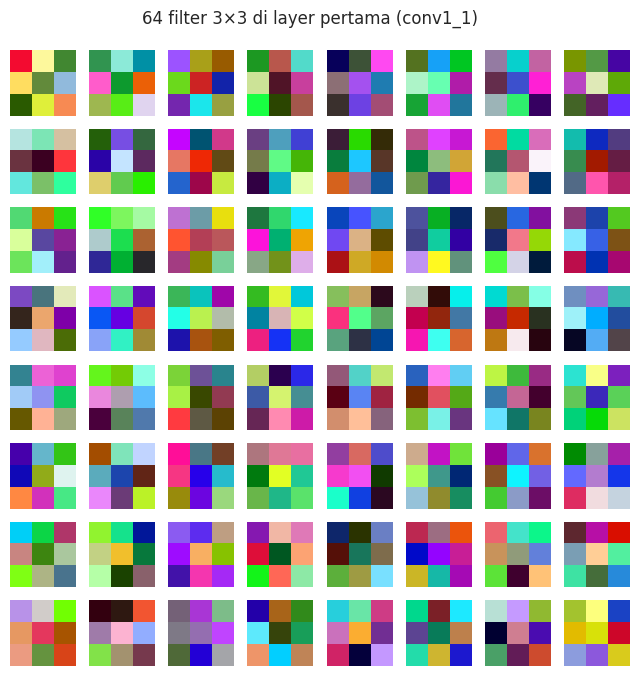

In [5]:
W = model.features[0].weight.detach().cpu()          # (64, 3, 3, 3)
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for ax, w in zip(axes.ravel(), W):
    w = (w - w.min()) / (w.max() - w.min() + 1e-8)
    ax.imshow(w.permute(1, 2, 0).numpy(), interpolation="nearest"); ax.axis("off")
plt.suptitle("64 filter 3×3 di layer pertama (conv1_1)", y=0.93)
save_fig(fig, "vgg_filter_layer1.png"); plt.show()

## 2. Data Test & Pemeriksaan Bobot

Kita memuat **data test yang sama** seperti saat training (folder `test`) dan menghitung akurasinya. Ini sekaligus **pemeriksaan bahwa bobot dimuat dengan benar**: pada run 25 epoch, akurasi VGG16 di test set seharusnya **±98,52%** (run 12 epoch: ±97,75%).

> Catatan: gambar di folder output notebook (grafik .png) sengaja diabaikan agar tidak ikut terbaca sebagai data.

In [6]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def label_from_path(p: Path):
    folder, fname = p.parent.name.lower(), p.name.lower()
    for s in (folder, fname):
        if s.startswith("cat"): return 0
        if s.startswith("dog"): return 1
    return None

def split_from_path(p: Path):
    parts = [x.lower() for x in p.parent.parts]
    if any("train" in x for x in parts): return "train"
    if any("test" in x for x in parts):  return "test"
    return None

weights_dir = WEIGHTS_PATH.parent
records = []
for p in Path(DATA_ROOT).rglob("*"):
    if p.suffix.lower() not in IMG_EXT: continue
    if weights_dir in p.parents: continue            # abaikan gambar hasil notebook (grafik .png)
    if split_from_path(p) != "test": continue
    y = label_from_path(p)
    if y is not None:
        records.append((str(p), y))
test_df = pd.DataFrame(records, columns=["path", "label"])
assert len(test_df) > 0, "Data test tidak ketemu. Pastikan dataset Cat or Dog sudah di-Add Input."
print("Jumlah gambar test:", len(test_df), "| cat:", int((test_df.label == 0).sum()), "| dog:", int((test_df.label == 1).sum()))

def load_img(path):
    try:
        with Image.open(path) as im:
            return np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)
    except Exception:
        return None

paths, labels = test_df["path"].tolist(), test_df["label"].tolist()
with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as ex:
    arrs = list(tqdm(ex.map(load_img, paths), total=len(paths), desc="load test"))
keep = [i for i, a in enumerate(arrs) if a is not None]
X_test = torch.from_numpy(np.stack([arrs[i] for i in keep])).permute(0, 3, 1, 2).contiguous()   # (N,3,H,W) uint8
y_true = np.array([labels[i] for i in keep])
test_paths = [paths[i] for i in keep]
print("X_test:", tuple(X_test.shape))

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1) * 255
def normalize(xb_uint8):
    return (xb_uint8.to(DEVICE).float() - MEAN) / STD

@torch.no_grad()
def predict_proba(X, bs=128):
    model.eval(); out = []
    for s in range(0, len(X), bs):
        out.append(F.softmax(model(normalize(X[s:s + bs])), dim=1).cpu())
    return torch.cat(out).numpy()

probs_all = predict_proba(X_test)
y_pred = probs_all.argmax(1)
acc = (y_pred == y_true).mean()
print(f"\nAkurasi test: {acc * 100:.2f}%  (harapan: ±98,52% untuk 25 epoch, ±97,75% untuk 12 epoch)")

Jumlah gambar test: 3863 | cat: 1944 | dog: 1919


load test:   0%|          | 0/3863 [00:00<?, ?it/s]

X_test: (3863, 3, 128, 128)

Akurasi test: 98.52%  (harapan: ±98,52% untuk 25 epoch, ±97,75% untuk 12 epoch)


## 3. Input & Preprocessing

Model **tidak** menerima file JPG mentah. Ada tiga langkah sebelum gambar masuk ke layer pertama:

1. **Resize** ke 128×128: model butuh ukuran input tetap, dan ini juga mempercepat komputasi.
2. **Ubah jadi tensor** berukuran `3 × 128 × 128`: 3 kanal warna (R, G, B), masing-masing matriks 128×128 berisi nilai 0 sampai 255.
3. **Normalisasi:** tiap kanal dikurangi *mean* dan dibagi *std* (nilai standar ImageNet). Hasilnya nilai kira-kira berpusat di 0 dengan rentang ±2,5. Ini membuat training stabil dan cepat.

Rumus normalisasi: `x_norm = (x − mean) / std`

Contoh yang dipakai: indeks 3214 | label asli: dog | file: dog.4802.jpg
Tensor input ke model: shape=(1, 3, 128, 128) | min=-2.05 | max=2.64 | mean=0.59


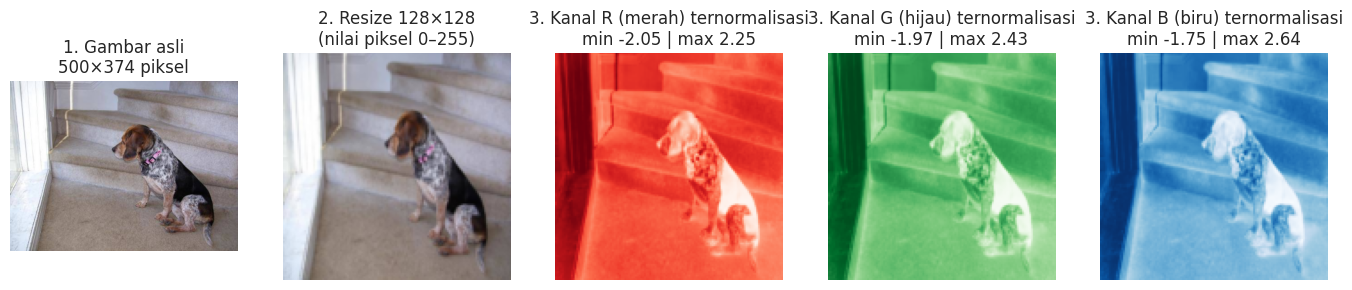

In [7]:
rng = np.random.RandomState(SEED)
correct_idx = np.where(y_pred == y_true)[0]
ex = EXAMPLE_IDX if EXAMPLE_IDX is not None else int(rng.choice(correct_idx))
print(f"Contoh yang dipakai: indeks {ex} | label asli: {CLASS_NAMES[y_true[ex]]} | file: {Path(test_paths[ex]).name}")

orig = Image.open(test_paths[ex]).convert("RGB")
img_u8 = X_test[ex]                                    # (3,128,128) uint8
x = normalize(img_u8.unsqueeze(0))                     # (1,3,128,128) float, ternormalisasi
print(f"Tensor input ke model: shape={tuple(x.shape)} | min={x.min().item():.2f} | max={x.max().item():.2f} | mean={x.mean().item():.2f}")

fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
axes[0].imshow(orig); axes[0].set_title(f"1. Gambar asli\n{orig.size[0]}×{orig.size[1]} piksel")
axes[1].imshow(img_u8.permute(1, 2, 0).numpy()); axes[1].set_title("2. Resize 128×128\n(nilai piksel 0–255)")
for k, (nm, cm) in enumerate([("R (merah)", "Reds"), ("G (hijau)", "Greens"), ("B (biru)", "Blues")]):
    ch = x[0, k].cpu().numpy()
    axes[2 + k].imshow(ch, cmap=cm)
    axes[2 + k].set_title(f"3. Kanal {nm} ternormalisasi\nmin {ch.min():.2f} | max {ch.max():.2f}")
for a in axes: a.axis("off")
save_fig(fig, "vgg_preprocessing.png"); plt.show()

## 4. Proses Konvolusi: Apa yang "Dilihat" Tiap Blok?

Di bawah ini kita tampilkan **feature map** (keluaran) dari akhir tiap blok untuk gambar contoh yang sama. Setiap kotak kecil adalah **satu channel** (satu filter) yang menunjukkan *di mana pola tertentu aktif* di gambar. Terang = aktif kuat.

Untuk tiap blok kita tampilkan **8 channel paling aktif** dan **rata-rata seluruh channel** (kolom terakhir).

### Cara membaca
| Blok | Ukuran | Yang umumnya dipelajari |
|---|---|---|
| 1 | 64×128×128 | **Tepi & gradien warna**: masih mirip gambar asli |
| 2 | 128×64×64 | **Tekstur sederhana, sudut, pola berulang** |
| 3 | 256×32×32 | **Bagian objek** (pola bulu, mata, kontur) |
| 4 | 512×16×16 | **Bagian objek yang lebih kompleks** (telinga, moncong) |
| 5 | 512×8×8 | **Konsep tingkat tinggi**: sulit dikenali manusia, tapi sangat informatif untuk klasifikasi |

Semakin dalam: gambar makin **kecil**, tapi tiap "piksel" membawa **informasi makin abstrak** (tidak lagi "warna", melainkan "seberapa mirip dengan telinga/moncong/bulu"). (Pola per blok ini adalah temuan umum dari studi visualisasi CNN; pada model kita bisa berbeda-beda detailnya.)

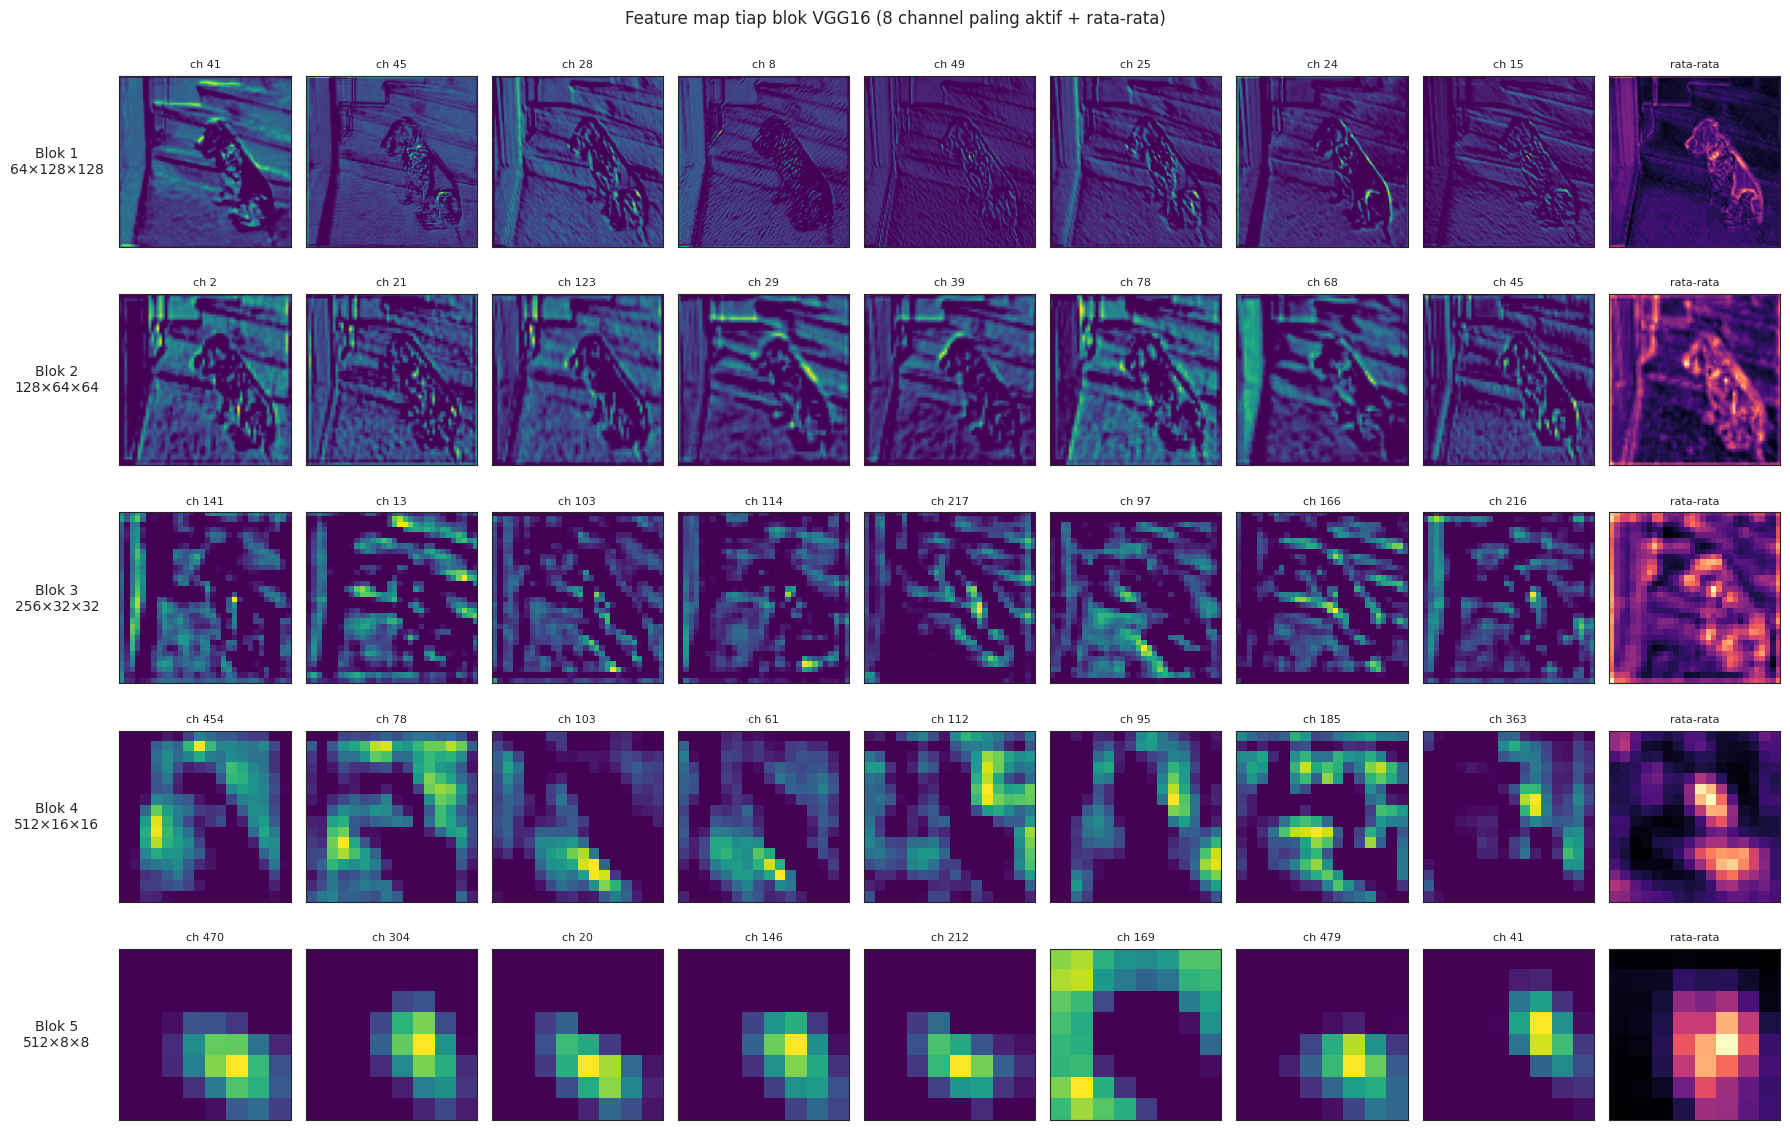

In [8]:
BLOCK_LAST_RELU = {}
for i, n in enumerate(LAYER_NAMES):
    if n.startswith("relu"):
        BLOCK_LAST_RELU[int(n[4])] = i                 # relu terakhir tiap blok (relu1_2, relu2_2, relu3_3, ...)

acts, handles = {}, []
for b, i in BLOCK_LAST_RELU.items():
    handles.append(model.features[i].register_forward_hook(
        lambda m, inp, out, b=b: acts.__setitem__(b, out.detach().cpu())))
with torch.no_grad():
    _ = model(x)
for h in handles: h.remove()

N_SHOW = 8
fig, axes = plt.subplots(5, N_SHOW + 1, figsize=(2.0 * (N_SHOW + 1), 2.3 * 5))
for b in range(1, 6):
    a = acts[b][0]                                      # (C,H,W)
    top = a.mean(dim=(1, 2)).argsort(descending=True)[:N_SHOW]
    for j, ch in enumerate(top):
        axes[b - 1, j].imshow(a[ch].numpy(), cmap="viridis")
        axes[b - 1, j].set_title(f"ch {int(ch)}", fontsize=8)
    axes[b - 1, N_SHOW].imshow(a.mean(0).numpy(), cmap="magma")
    axes[b - 1, N_SHOW].set_title("rata-rata", fontsize=8)
    axes[b - 1, 0].set_ylabel(f"Blok {b}\n{a.shape[0]}×{a.shape[1]}×{a.shape[2]}", fontsize=10, rotation=0, labelpad=45, va="center")
    for ax in axes[b - 1]:
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Feature map tiap blok VGG16 (8 channel paling aktif + rata-rata)", y=0.995)
plt.tight_layout()
save_fig(fig, "vgg_feature_maps.png"); plt.show()

### Yang terjadi di dalam satu layer konvolusi (untuk dijelaskan)
1. **Conv 3×3:** sebuah filter 3×3 digeser di seluruh gambar; di tiap posisi dihitung penjumlahan perkalian (*dot product*) dengan piksel di bawahnya. Hasilnya satu feature map. Dengan 64 filter → 64 feature map.
2. **BatchNorm:** menormalkan hasil tiap channel agar training stabil dan cepat.
3. **ReLU:** `max(0, x)`; nilai negatif dibuang, sehingga hanya pola yang "aktif" yang dilanjutkan. Ini memberi **non-linearitas**.
4. **Max-pooling 2×2 (di akhir blok):** dari tiap kotak 2×2 diambil nilai terbesar, jadi ukuran dibagi dua. Fitur utama dipertahankan, detail posisi tepat dibuang sedikit (memberi toleransi terhadap pergeseran kecil).

**Kenapa selalu 3×3?** Dua conv 3×3 berurutan punya receptive field setara satu conv 5×5, dan tiga conv 3×3 setara 7×7, tetapi dengan **parameter lebih sedikit** dan **lebih banyak ReLU** (lebih ekspresif). Itulah ide inti VGG.

## 5. Classifier & Output

Keluaran blok 5 berukuran `512 × 4 × 4`. Classifier mengubahnya jadi keputusan:

1. **Flatten:** diratakan jadi satu vektor `512×4×4 = 8192` angka.
2. **FC1 (8192 → 4096) + ReLU + Dropout:** mengombinasikan semua fitur untuk membentuk representasi tingkat tinggi.
3. **FC2 (4096 → 4096) + ReLU + Dropout:** pengolahan lanjutan.
4. **FC3 (4096 → 2):** menghasilkan **2 skor mentah** (*logit*), satu untuk cat, satu untuk dog.
5. **Softmax:** mengubah logit jadi probabilitas yang jumlahnya 1: `p_i = e^{z_i} / Σ e^{z_j}`. Kelas dengan probabilitas tertinggi adalah **prediksi**.

*Dropout* hanya aktif saat training (mematikan 50% neuron secara acak untuk mencegah overfitting). Saat inferensi seperti di sini, dropout **tidak aktif**.

features (blok 1–5)    -> (1, 512, 4, 4)
flatten                -> (1, 8192)
fc1                    -> (1, 4096)
relu_fc1               -> (1, 4096)
dropout1               -> (1, 4096)
fc2                    -> (1, 4096)
relu_fc2               -> (1, 4096)
dropout2               -> (1, 4096)
fc3 (output)           -> (1, 2)

Logit  : cat = -8.090 | dog = +5.644
Softmax: cat = 0.00% | dog = 100.00%
Prediksi: dog  (label asli: dog)


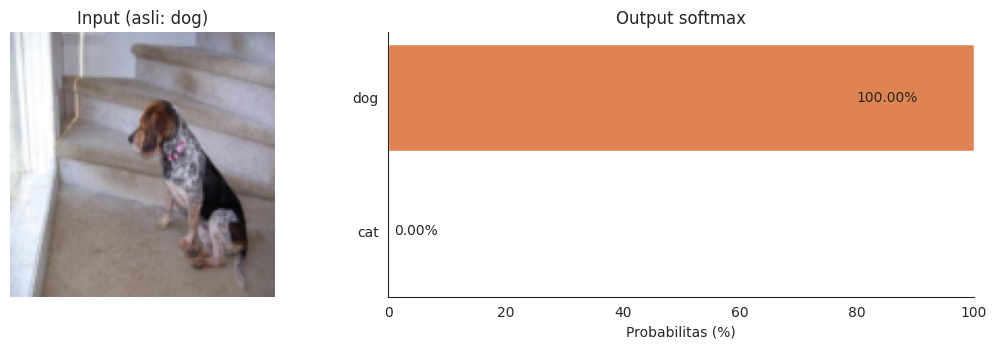

In [9]:
with torch.no_grad():
    h = model.features(x)
    print(f"{'features (blok 1–5)':22s} -> {tuple(h.shape)}")
    for nm, layer in zip(CLS_NAMES, model.classifier):
        h = layer(h)
        print(f"{nm:22s} -> {tuple(h.shape)}")
logits = h[0].cpu()
probs_ex = F.softmax(logits, dim=0).numpy()
print(f"\nLogit  : cat = {logits[0]:+.3f} | dog = {logits[1]:+.3f}")
print(f"Softmax: cat = {probs_ex[0] * 100:.2f}% | dog = {probs_ex[1] * 100:.2f}%")
print(f"Prediksi: {CLASS_NAMES[int(probs_ex.argmax())]}  (label asli: {CLASS_NAMES[y_true[ex]]})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].imshow(img_u8.permute(1, 2, 0).numpy()); axes[0].axis("off")
axes[0].set_title(f"Input (asli: {CLASS_NAMES[y_true[ex]]})")
bars = axes[1].barh(CLASS_NAMES, probs_ex * 100, color=["#4C72B0", "#DD8452"])
axes[1].set_xlim(0, 100); axes[1].set_xlabel("Probabilitas (%)"); axes[1].set_title("Output softmax")
for bar, p in zip(bars, probs_ex):
    axes[1].text(min(bar.get_width() + 1, 80), bar.get_y() + bar.get_height() / 2, f"{p * 100:.2f}%", va="center")
sns.despine(ax=axes[1])
plt.tight_layout(); save_fig(fig, "vgg_output_softmax.png"); plt.show()

## 6. Grad-CAM: Model Melihat ke Mana?

Pertanyaan: *"Dari seluruh gambar, bagian mana yang membuat model memutuskan 'cat' atau 'dog'?"*

**Grad-CAM** menjawabnya dengan langkah ini:
1. Ambil feature map terakhir (`relu5_3`, ukuran 512×8×8).
2. Hitung **gradien** skor kelas yang diprediksi terhadap feature map itu. Gradien menunjukkan channel mana yang **paling berpengaruh** pada keputusan.
3. Rata-ratakan gradien per channel → jadi **bobot penting** tiap channel.
4. Jumlahkan feature map berbobot lalu ReLU → **peta panas 8×8**, lalu di-*upsample* ke 128×128 dan ditumpuk di atas gambar.

**Warna merah/kuning = area yang paling mempengaruhi keputusan.** Kalau model sehat, area itu biasanya wajah/tubuh hewan, bukan latar belakang.

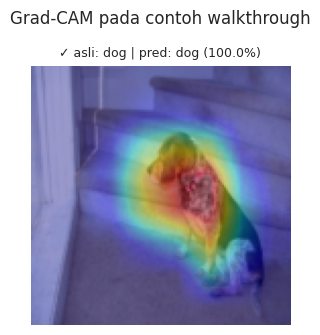

In [10]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._fwd)
    def _fwd(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, class_idx=None):
        with torch.enable_grad():
            self.model.zero_grad()
            logits = self.model(x)
            idx = int(logits.argmax(1)) if class_idx is None else class_idx
            logits[0, idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
        cam = cam.detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        probs = F.softmax(logits.detach(), dim=1)[0].cpu().numpy()
        return cam, probs, idx

cam_engine = GradCAM(model, model.features[BLOCK_LAST_RELU[5]])

def show_cam_grid(indices, title, ncols=6, fname=None):
    n = len(indices); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 3.3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, i in zip(axes, indices):
        cam, p, pred = cam_engine(normalize(X_test[i].unsqueeze(0)))
        ax.imshow(X_test[i].permute(1, 2, 0).numpy()); ax.imshow(cam, cmap="jet", alpha=0.4)
        ok = "✓" if pred == y_true[i] else "✗"
        ax.set_title(f"{ok} asli: {CLASS_NAMES[y_true[i]]} | pred: {CLASS_NAMES[pred]} ({p[pred] * 100:.1f}%)", fontsize=9)
        ax.axis("off")
    for ax in axes[n:]: ax.axis("off")
    plt.suptitle(title, y=1.0); plt.tight_layout()
    if fname: save_fig(fig, fname)
    plt.show()

# contoh yang dipakai pada walkthrough di atas
show_cam_grid([ex], "Grad-CAM pada contoh walkthrough", ncols=1, fname="vgg_gradcam_contoh.png")

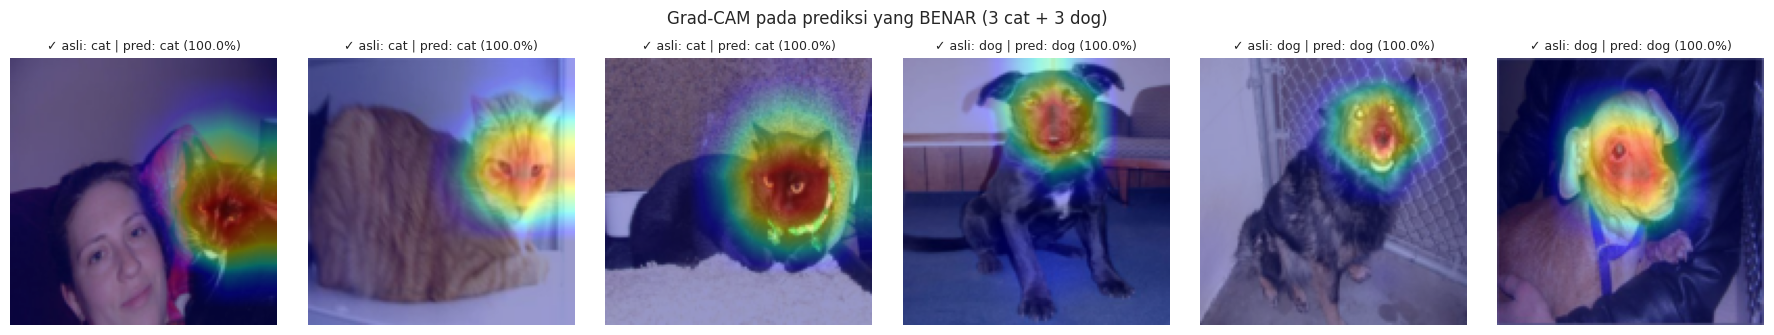

In [11]:
cats_ok = rng.choice(np.where((y_pred == y_true) & (y_true == 0))[0], 3, replace=False)
dogs_ok = rng.choice(np.where((y_pred == y_true) & (y_true == 1))[0], 3, replace=False)
show_cam_grid(list(cats_ok) + list(dogs_ok), "Grad-CAM pada prediksi yang BENAR (3 cat + 3 dog)", fname="vgg_gradcam_benar.png")

## 7. Evaluasi Menyeluruh
### 7.1 Classification report & confusion matrix

              precision    recall  f1-score   support

         cat     0.9851    0.9856    0.9853      1944
         dog     0.9854    0.9849    0.9851      1919

    accuracy                         0.9852      3863
   macro avg     0.9852    0.9852    0.9852      3863
weighted avg     0.9852    0.9852    0.9852      3863



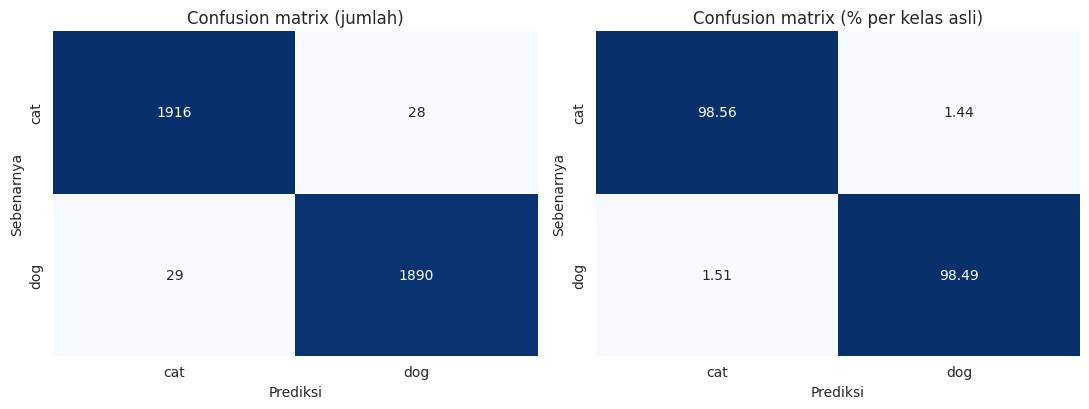

Total salah: 57 dari 3863 gambar


In [12]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_title("Confusion matrix (jumlah)"); axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Sebenarnya")
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[1], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[1].set_title("Confusion matrix (% per kelas asli)"); axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Sebenarnya")
plt.tight_layout(); save_fig(fig, "vgg_confusion_matrix.png"); plt.show()
print(f"Total salah: {int((y_pred != y_true).sum())} dari {len(y_true)} gambar")

### 7.2 ROC curve & kepercayaan model
- **ROC curve:** menunjukkan kemampuan model membedakan kelas pada semua ambang batas. **AUC mendekati 1 = hampir sempurna.**
- **Histogram kepercayaan:** seberapa yakin model pada prediksinya. Model yang baik **yakin saat benar** dan **kurang yakin saat salah**.

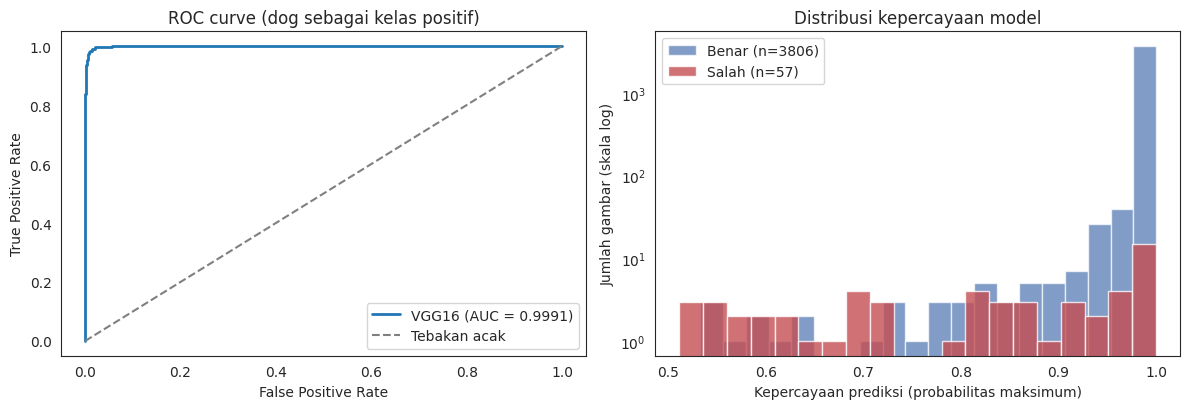

AUC = 0.9991 | rata-rata kepercayaan saat benar = 99.6% | saat salah = 81.6%


In [13]:
fpr, tpr, _ = roc_curve(y_true, probs_all[:, 1])
roc_auc = auc(fpr, tpr)
conf = probs_all.max(1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(fpr, tpr, lw=2, label=f"VGG16 (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curve (dog sebagai kelas positif)"); axes[0].legend(loc="lower right")
ok = y_pred == y_true
axes[1].hist(conf[ok], bins=20, alpha=0.7, label=f"Benar (n={ok.sum()})", color="#4C72B0")
axes[1].hist(conf[~ok], bins=20, alpha=0.8, label=f"Salah (n={(~ok).sum()})", color="#C44E52")
axes[1].set_yscale("log"); axes[1].set_xlabel("Kepercayaan prediksi (probabilitas maksimum)")
axes[1].set_ylabel("Jumlah gambar (skala log)"); axes[1].set_title("Distribusi kepercayaan model"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "vgg_roc_confidence.png"); plt.show()
print(f"AUC = {roc_auc:.4f} | rata-rata kepercayaan saat benar = {conf[ok].mean() * 100:.1f}% | saat salah = {conf[~ok].mean() * 100:.1f}%")

### 7.3 Analisis kesalahan: kenapa model salah?
Kita lihat **kesalahan dengan kepercayaan tertinggi** (model yakin tapi salah) beserta Grad-CAM-nya. Biasanya penyebabnya: gambar kabur atau terlalu kecil, hewan tertutup sebagian, ada beberapa objek, pose tidak biasa, ras mirip, atau **label dataset yang keliru**. Periksa sendiri gambarnya dan simpulkan.

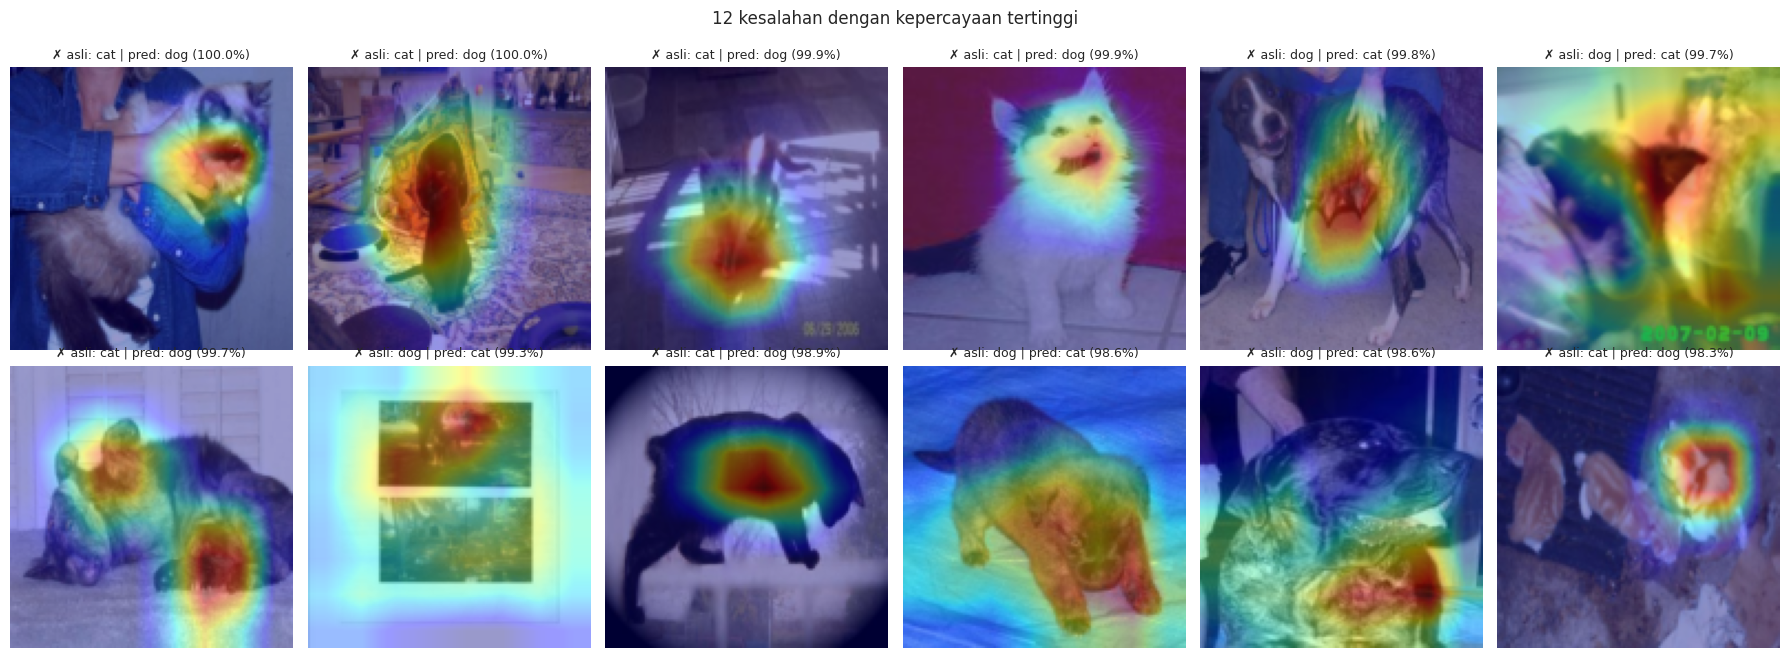

In [14]:
wrong = np.where(y_pred != y_true)[0]
if len(wrong) > 0:
    order = wrong[np.argsort(-probs_all[wrong, y_pred[wrong]])]
    show_cam_grid(list(order[:12]), "12 kesalahan dengan kepercayaan tertinggi", fname="vgg_gradcam_salah.png")
else:
    print("Tidak ada kesalahan prediksi.")

## 8. Demo: Coba Gambar Sendiri
Kamu bisa menguji dengan foto sendiri: di Kaggle klik **Upload → New Dataset**, upload foto kucing/anjing, lalu **Add Input** dan isi `MY_IMAGE_DIR` di sel konfigurasi dengan foldernya (mis. `"/kaggle/input/foto-saya"`). Kalau dibiarkan `None`, sel ini memakai 4 gambar acak dari data test.

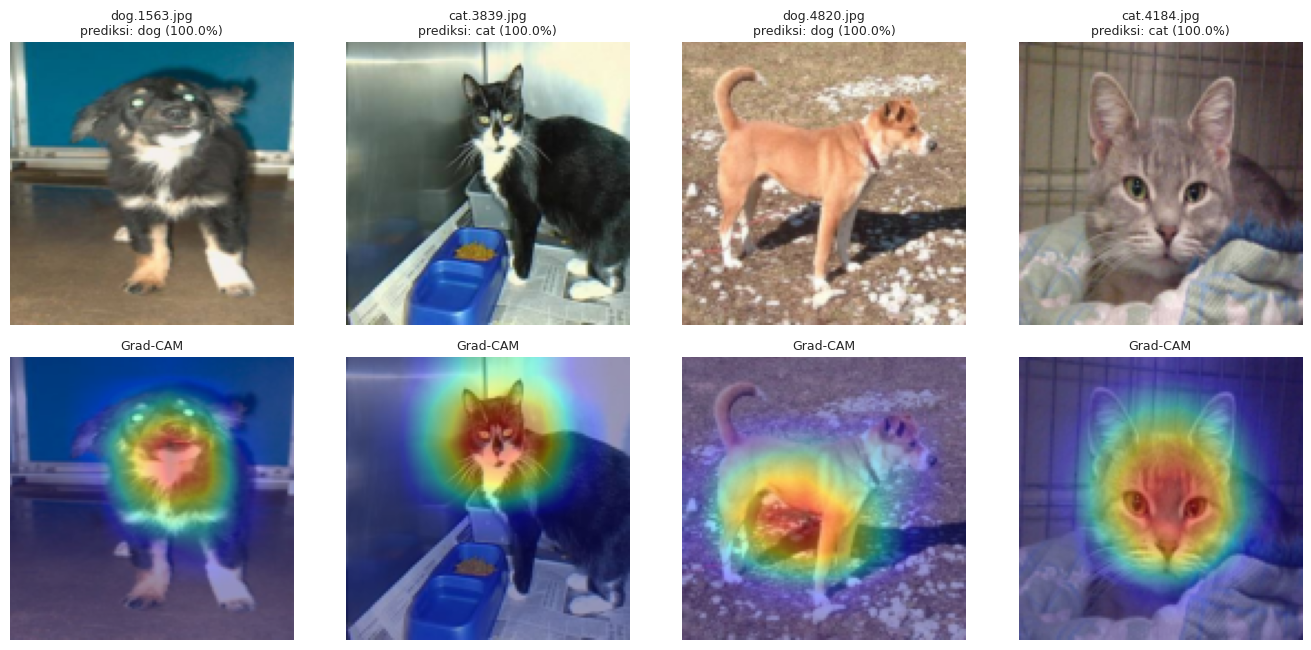

In [15]:
def run_on_pil(img):
    arr = np.asarray(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)
    xt = normalize(torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0))
    cam, probs, pred = cam_engine(xt)
    return arr, cam, probs, pred

if MY_IMAGE_DIR:
    demo_paths = [str(p) for p in sorted(Path(MY_IMAGE_DIR).rglob("*")) if p.suffix.lower() in IMG_EXT][:8]
else:
    demo_paths = [test_paths[i] for i in rng.choice(len(test_paths), 4, replace=False)]
assert demo_paths, "Tidak ada gambar untuk demo."

fig, axes = plt.subplots(2, len(demo_paths), figsize=(3.4 * len(demo_paths), 6.6), squeeze=False)
for k, pth in enumerate(demo_paths):
    arr, cam, probs, pred = run_on_pil(Image.open(pth))
    axes[0, k].imshow(arr); axes[0, k].axis("off")
    axes[0, k].set_title(f"{Path(pth).name[:22]}\nprediksi: {CLASS_NAMES[pred]} ({probs[pred] * 100:.1f}%)", fontsize=9)
    axes[1, k].imshow(arr); axes[1, k].imshow(cam, cmap="jet", alpha=0.4); axes[1, k].axis("off")
    axes[1, k].set_title("Grad-CAM", fontsize=9)
plt.tight_layout(); save_fig(fig, "vgg_demo.png"); plt.show()

## 9. Ringkasan untuk Presentasi

### Alur singkat (1 kalimat per tahap)
1. **Input:** gambar di-resize 128×128, diubah jadi tensor 3×128×128, lalu dinormalisasi.
2. **Blok 1–2:** filter 3×3 menangkap **tepi, warna, dan tekstur** sederhana.
3. **Blok 3–4:** fitur digabung menjadi **bagian objek** (bulu, telinga, moncong).
4. **Blok 5:** menghasilkan **representasi abstrak** 512×4×4 yang membawa informasi kelas.
5. **Classifier:** 3 layer FC (8192 → 4096 → 4096 → 2) menghasilkan 2 skor.
6. **Output:** softmax mengubah skor jadi probabilitas; kelas dengan probabilitas tertinggi adalah prediksi.

### Fakta kunci VGG16 pada eksperimen kita
- **Akurasi test ±98,5%**, **F1 ±98,5%**, hanya sekitar **57 salah dari 3.863 gambar** (run 25 epoch).
- **65,07 juta parameter**, ±77% di antaranya ada di layer fully-connected.
- Training paling lama di antara model kita (±24 menit) dan inferensi paling lambat (±1,2 ms/gambar).
- Selisih akurasi dari GoogLeNet/ResNet-18 sangat tipis, sementara kedua model itu jauh lebih ringan.

### Kemungkinan pertanyaan dosen
- **Kenapa semua conv 3×3?** Hemat parameter dan receptive field tetap besar saat ditumpuk; lebih banyak non-linearitas.
- **Kenapa ada BatchNorm?** Pada versi asli tidak ada; ditambahkan agar bisa dilatih dari nol dengan stabil.
- **Apa fungsi pooling?** Memperkecil ukuran, mempertahankan fitur kuat, memberi toleransi pergeseran.
- **Kenapa jumlah filter naik terus?** Semakin dalam, ukuran spasial mengecil, jadi jumlah fitur dinaikkan untuk menjaga kapasitas representasi.
- **Bagaimana kita tahu model melihat bagian yang benar?** Dengan Grad-CAM (bagian 6).
- **Kelemahan VGG16?** Parameter besar (terutama FC), lambat, memori besar, rawan overfitting.